# Tier 2 — Heartbeat diagnosis from a single-lead ECG

**Why a second dataset?** On the clinical dataset (tier 1), every model and every combination of models
plateaus at about 73 % accuracy, because 11 exam variables cannot separate CVD from no CVD any better.
To reach the > 95 % target honestly, the system adds a **diagnosis tier**: when a patient is flagged at risk,
a single-lead ECG (wearable / Holter) is analysed beat by beat.

**Data:** PhysioNet *MIT-BIH Arrhythmia Database* (48 records, 360 Hz) and *MIT-BIH Supraventricular
Arrhythmia Database* (78 records, 128 Hz). Every beat is labelled by cardiologists. Licence: ODC-By 1.0.
**Task:** normal beat (AAMI class N) vs. abnormal beat (AAMI classes S, V, F).

Every step is recorded in `outputs/ecg/` (`TRACEABILITY.md`, `run_manifest.json`).

In [1]:
# --- Setup -------------------------------------------------------------
# Local: run from ml-pipeline/notebooks with the project's virtual environment.
# Google Colab: uncomment the next three lines (replace <repo-url>).
# !git clone <repo-url> repo
# %cd repo/ml-pipeline/notebooks
# !pip install -q -r ../requirements.txt
import json, sys, warnings
sys.path.insert(0, "..")
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", message=".*sklearn.utils.parallel.delayed.*")
%matplotlib inline
import pandas as pd
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
from cardio_ml import config
from cardio_ml.workflows import ECGDiagnosisWorkflow
wf = ECGDiagnosisWorkflow(show=True)

## 1. Extraction and transformation of an unstructured signal (ETL)

For each record: read lead 0 (MLII), apply a 0.5–40 Hz Butterworth band-pass filter (zero phase),
resample to 128 Hz, align every annotated R peak to the beat's main deflection (±75 ms), then cut a
window of 0.25 s before and 0.45 s after it.
Rhythm features come from the RR intervals. **Patient-relative features** compare each beat with the
patient's own dominant beat (median template, built without labels), the way a cardiologist spots an
ectopic beat. Paced records (102, 104, 107, 217) are excluded, as the AAMI EC57 standard recommends.
The databases are downloaded from PhysioNet automatically the first time.

In [2]:
wf.ingest()
wf.raw[['database', 'record', 'symbol', 'aami_class', 'pre_rr', 'post_rr', 'rr_ratio', 'amplitude_mv', 'abnormal']].head()

[ecg] Segment beats (mitdb): 0 -> 100,630 rows. 44 records read, 4 paced records excluded (102, 104, 107, 217)


[ecg] Segment beats (svdb): 0 -> 184,347 rows. 78 records read, 0 paced records excluded (none)


,database,record,symbol,aami_class,pre_rr,post_rr,rr_ratio,amplitude_mv,abnormal
0,mitdb,mitdb_100,N,N,0.820312,0.812500,1.000000,1.346941,0
1,mitdb,mitdb_100,N,N,0.812500,0.789062,0.995215,1.296781,0
2,mitdb,mitdb_100,N,N,0.789062,0.789062,0.977419,1.288513,0
3,mitdb,mitdb_100,N,N,0.789062,0.789062,0.982968,1.187407,0
4,mitdb,mitdb_100,N,N,0.789062,0.812500,0.986328,1.219109,0


## 2. Cleaning and balancing
Beats with non-finite values or implausible RR intervals (outside 0.2–3.0 s, i.e. 20–300 bpm) are removed, then the classes are balanced 50/50.

In [3]:
wf.clean()
wf.tracker.lineage_frame()

[ecg] Remove non-finite values: 284,977 -> 284,977 rows. NaN or infinite values in any numeric column
[ecg] Filter implausible RR intervals (20-300 bpm): 284,977 -> 284,887 rows. pre_rr outside [0.2, 3.0]: 44; post_rr outside [0.2, 3.0]: 46
[ecg] Balance classes (random undersampling): 284,887 -> 65,414 rows. class counts {0: 252180, 1: 32707} -> {0: 32707, 1: 32707}


,step,rows_before,rows_after,detail,removed
0,Segment beats (mitdb),0,100630,"44 records read, 4 paced records excluded (102...",-100630
1,Segment beats (svdb),0,184347,"78 records read, 0 paced records excluded (none)",-184347
2,Remove non-finite values,284977,284977,NaN or infinite values in any numeric column,0
3,Filter implausible RR intervals (20-300 bpm),284977,284887,"pre_rr outside [0.2, 3.0]: 44; post_rr outside...",90
4,Balance classes (random undersampling),284887,65414,"class counts {0: 252180, 1: 32707} -> {0: 3270...",219473


## 3. Exploratory data analysis
An ETL example on a real signal, beats per class, mean beat shapes, rhythm features, correlations, VIF and a PCA projection.

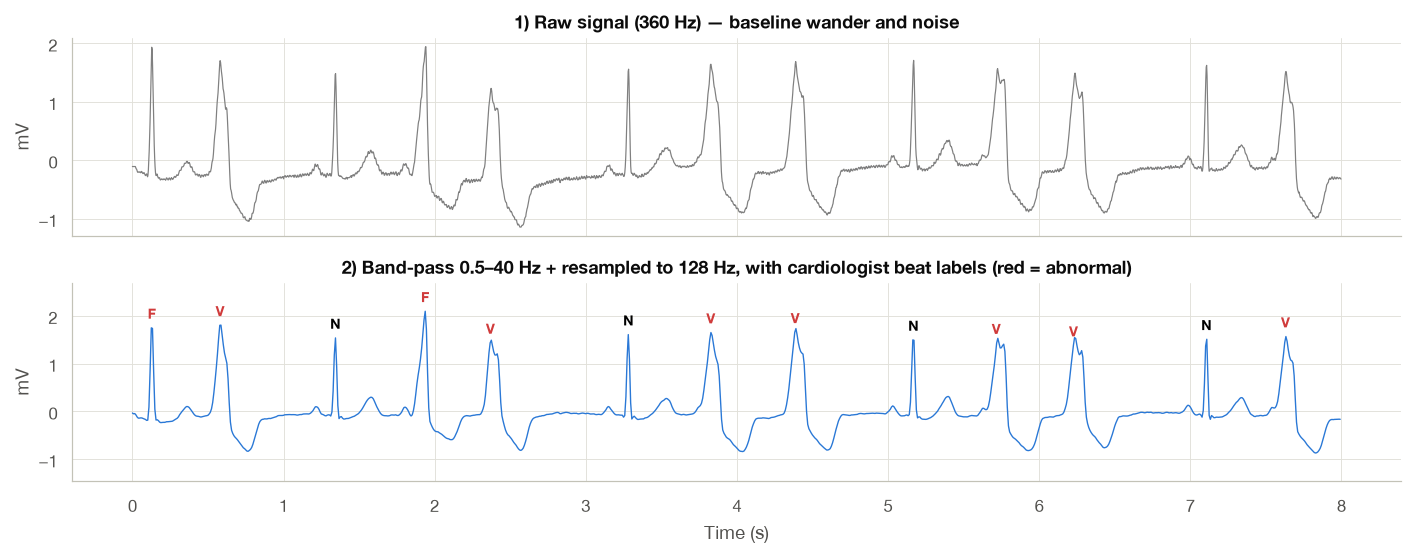

> **Figure 1 — ETL of an unstructured ECG signal: raw vs. filtered/resampled (MIT-BIH 208)**  
> *What it shows:* Top: the original signal with noise and wandering baseline; bottom: the filtered (0.5–40 Hz) and resampled 128 Hz signal, with the cardiologist's label on each beat.  
> *How to read it:* Red letters are abnormal beats (V ventricular, A/S supraventricular, F fusion). This is how an unstructured signal becomes table rows.

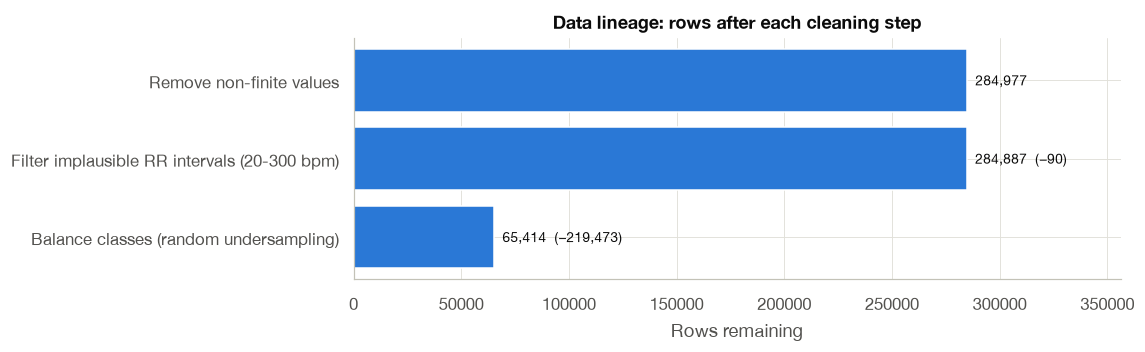

> **Figure 2 — Rows (beats) remaining after each ETL step**  
> *What it shows:* Each bar is the dataset after one cleaning step; in brackets, how many rows that step removed.  
> *How to read it:* Read it top to bottom. No row disappears without a reason: each step is explained in TRACEABILITY.md.

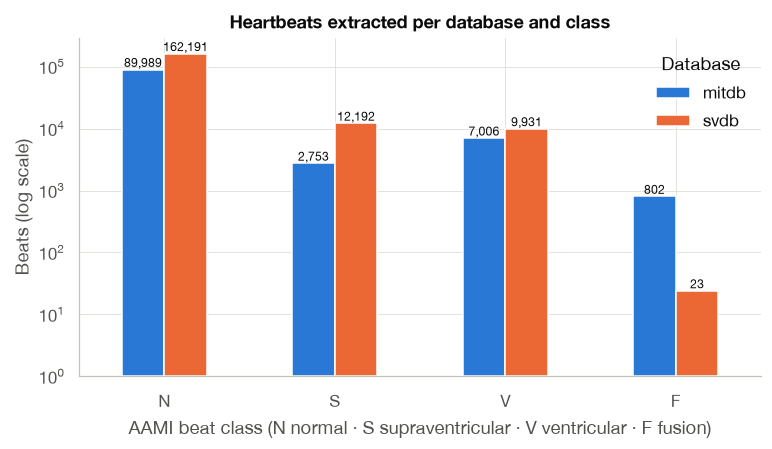

> **Figure 3 — Heartbeats per database and AAMI class before balancing**  
> *What it shows:* Number of beats of each AAMI class (N normal, S supraventricular, V ventricular, F fusion), on a log scale.  
> *How to read it:* Each axis tick is ×10. Normal beats are the vast majority: that is why balancing is needed.

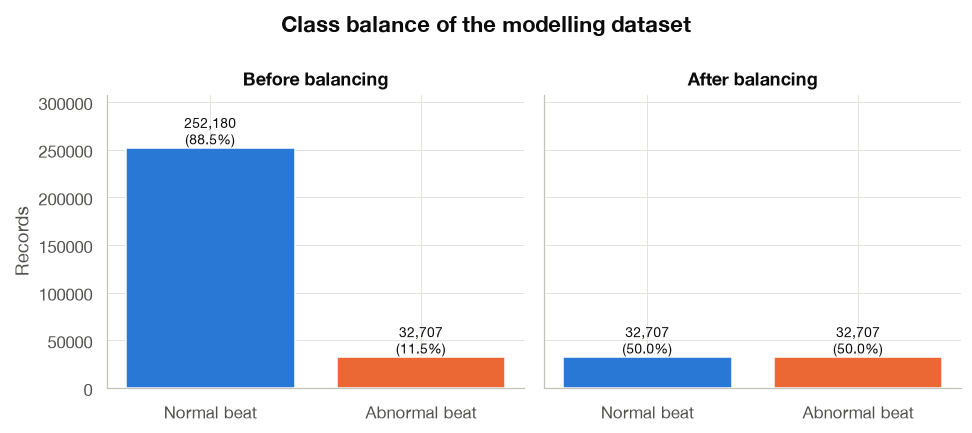

> **Figure 4 — Class balance before and after undersampling**  
> *What it shows:* How many cases of each class there are. All cases of the rarer class are kept and the same number is drawn at random from the common one (undersampling).  
> *How to read it:* On the right both bars must be equal (50/50). Accuracy cannot then be inflated by always answering the common class.

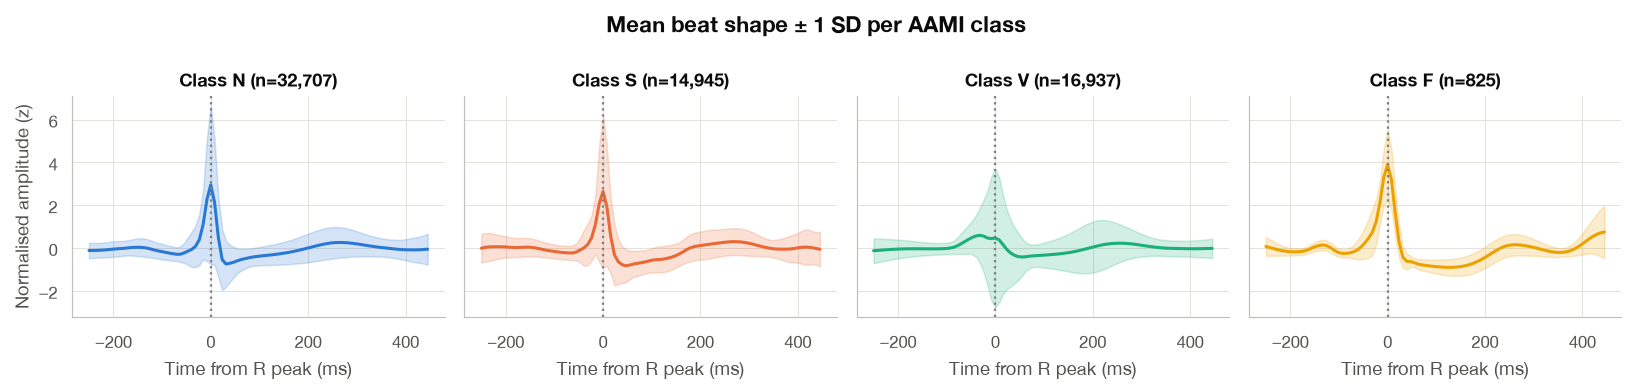

> **Figure 5 — Mean beat shape per AAMI class**  
> *What it shows:* Mean ± 1 standard deviation of the beat shape; time 0 is the R peak.  
> *How to read it:* The ventricular beat (V) is wide and deformed. The supraventricular (S) looks normal: that is why rhythm (when it arrives) is also used.

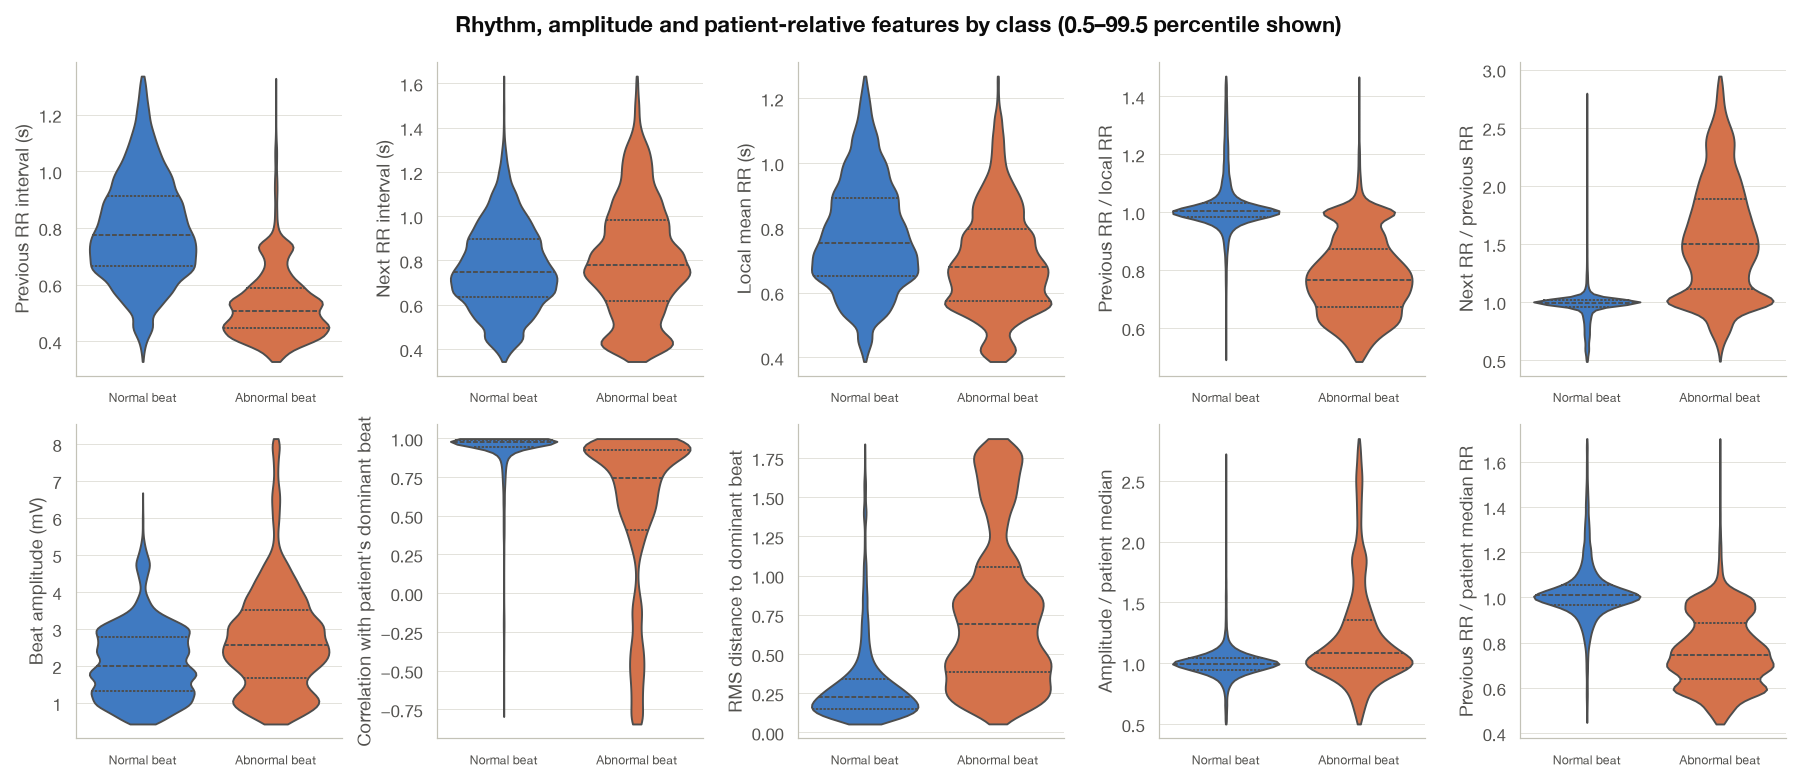

> **Figure 6 — RR and amplitude features by class**  
> *What it shows:* Violins of the rhythm (RR interval), amplitude and patient-relative features.  
> *How to read it:* Example: abnormal beats have rr_ratio < 1 (they arrive early) and lower similarity to the usual beat (template_corr).

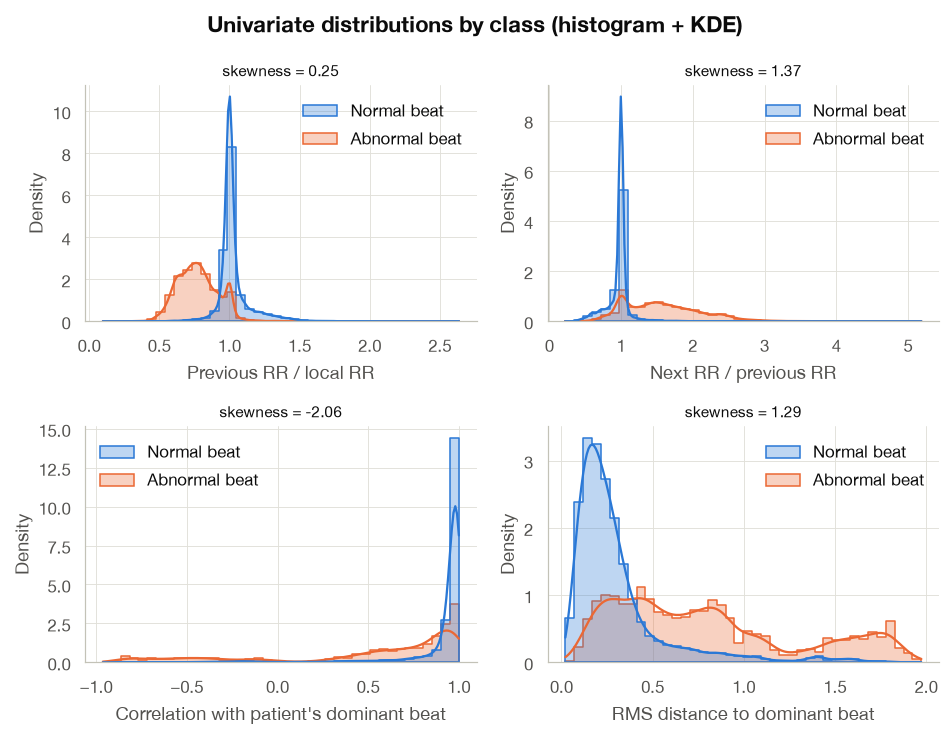

> **Figure 7 — Histograms and KDE of rhythm features by class**  
> *What it shows:* Histogram + KDE curve of the rhythm and similarity-to-usual-beat features.  
> *How to read it:* Curves that sit apart mark features that tell normal from abnormal beats.

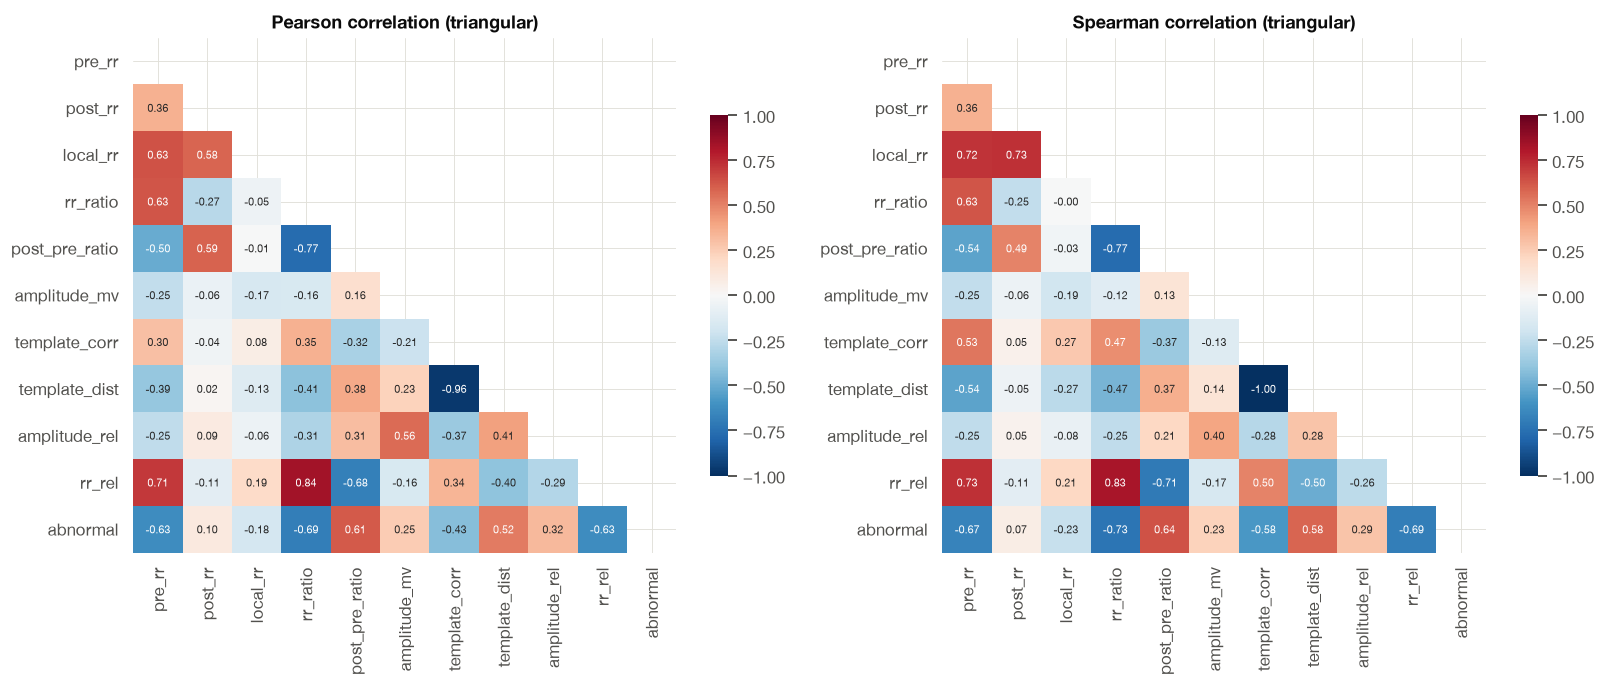

> **Figure 8 — Pearson vs. Spearman correlation of rhythm features**  
> *What it shows:* Pearson measures linear association; Spearman, ordered association (uses ranks, robust to outliers). From −1 to 1.  
> *How to read it:* Red: they rise together. Blue: one rises as the other falls. White: no relation. Look at the target's row.

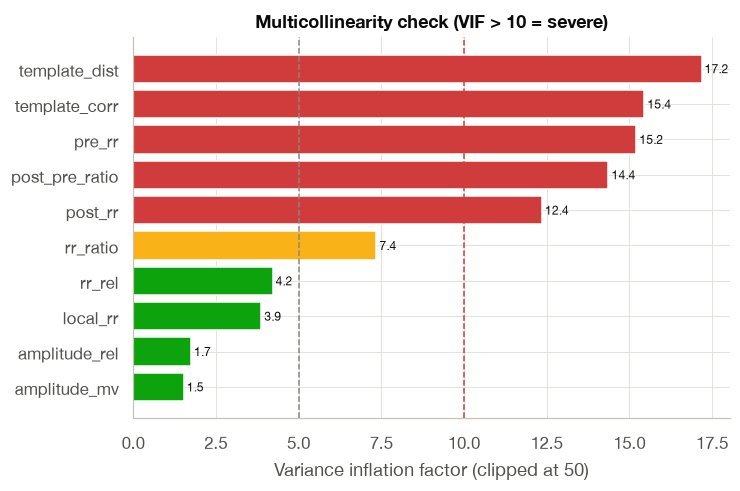

> **Figure 9 — Multicollinearity of the rhythm features (VIF)**  
> *What it shows:* VIF = 1 / (1 − R²) of the rhythm and amplitude features.  
> *How to read it:* Green < 5 fine, red > 10 severe. Tree models and regularisation tolerate moderate redundancy.

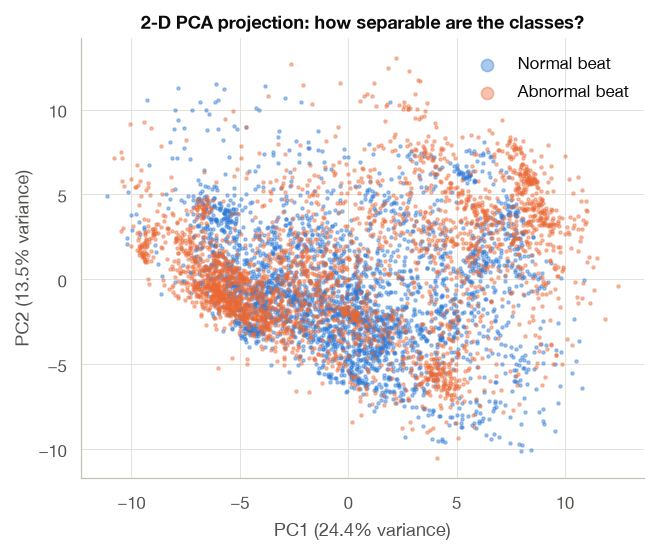

> **Figure 10 — 2-D PCA projection of all beat features by class**  
> *What it shows:* PCA summarises all variables in two axes that keep as much variation as possible.  
> *How to read it:* If the colours form separate clouds, the classes are easy to separate; if they mix, the problem is hard.

In [4]:
wf.explore()

## 4. Train / test split (by beat, stratified 80 / 20)

This is the standard split of MIT-BIH papers (*intra-patient* protocol) and gives the **official accuracy** of
tier 2: beats are shuffled and stratified, and the 20 % test beats are never used for training or tuning. The
patient of every training beat is kept, so the tuning (section 5) and the stacking out-of-fold predictions
(section 6) are grouped by patient. As an additional analysis, section 9 audits the patient overlap of this split
and measures the accuracy on completely **new** patients.

In [5]:
wf.split()

[ecg] Stratified train/test split: 65,414 -> 52,331 rows. train 52,331 / test 13,083 (20% held out, seed 42)


## 5. Hyperparameter tuning of the four base models
A randomized search with 3-fold CV on a 12,000-beat subsample. The folds are **grouped by patient**, so the
hyperparameters that win are the ones that generalise to new people, not the ones that memorise known ones.

In [6]:
wf.tune()
pd.Series({m.name: m.params for m in wf.models})

Tuning Logistic Regression ...


Tuning K-Nearest Neighbors ...


Tuning Random Forest ...


Tuning Support Vector Machine ...


Logistic Regression                           {'clf__C': 56.69849511478853}
K-Nearest Neighbors       {'clf__n_neighbors': 40, 'clf__p': 2, 'clf__we...
Random Forest             {'min_samples_leaf': 10, 'max_features': 'sqrt...
Support Vector Machine    {'clf__C': 0.3511356313970407, 'clf__gamma': 0...
dtype: object

## 6. Training: four independent models that reach one answer (stacking)

Each base model (LR, KNN, RF, SVM) is trained **on its own**. The models "communicate" through a
**meta-model** that receives their four probabilities and returns a single answer:

$$\hat P(\mathbf{x}) = \sigma\big(\beta_0 + \beta_1 p_{LR} + \beta_2 p_{KNN} + \beta_3 p_{RF} + \beta_4 p_{SVM}\big)$$

To keep the meta-model honest, it learns from **out-of-fold** probabilities (5-fold CV): every row
is scored by base models that never saw it. The coefficients $\beta_k$ show how much the system
trusts each model. The full derivation is in `docs/mathematical_model.md`, section 5.

In [7]:
wf.train()
wf.ensemble.weights()

Training level-0 models with out-of-fold predictions, then the meta-model ...


  Logistic Regression: OOF + final fit done in 2.9s


  K-Nearest Neighbors: OOF + final fit done in 1.8s


  Random Forest: OOF + final fit done in 53.8s


  Support Vector Machine: OOF + final fit done in 57.2s


{'intercept': -3.398022981408816,
 'LR': 1.6190051217806056,
 'KNN': 0.0,
 'RF': 6.265795050512607,
 'SVM': 0.0}

## 7. Evaluation on the held-out test set

Here the stacking ensemble is compared with each base model and with two simpler ways of
combining them (hard and soft voting). The metrics are accuracy, precision, recall, specificity,
F1, ROC-AUC, MCC and Brier score. The cell also reports a 95 % bootstrap confidence interval,
a McNemar test against the best base model, and the **referral rule**: a case whose final
probability falls in 0.35–0.65, or where the models split 2–2, goes to a clinician.

{
  "stacking_accuracy": 0.9686616219521517,
  "accuracy_95ci_low": 0.9656042192157762,
  "accuracy_95ci_high": 0.9717954597569365,
  "best_base_model": "Random Forest",
  "mcnemar_vs_best_base_p": 4.825421503937195e-13,
  "referral_rate": 0.03982267064129023,
  "accuracy_on_non_referred": 0.9780289762776628,
  "meets_95_target": true
}


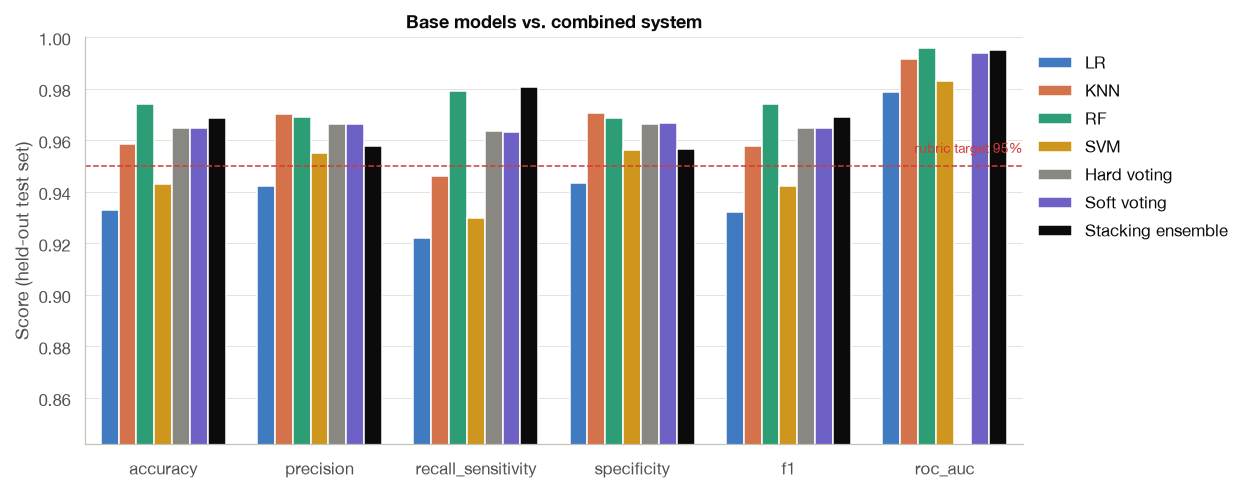

> **Figure 11 — Test-set metrics of the four base models, voting schemes and the stacking ensemble**  
> *What it shows:* Accuracy, precision, sensitivity, specificity, F1 and AUC on test beats not used for training, but from patients who did give other beats to training (split by beat).  
> *How to read it:* Higher is better; the red line is the 95 % target. This is the official evaluation (standard MIT-BIH protocol). The additional analysis on completely new patients is in the 'Leakage check' figure.

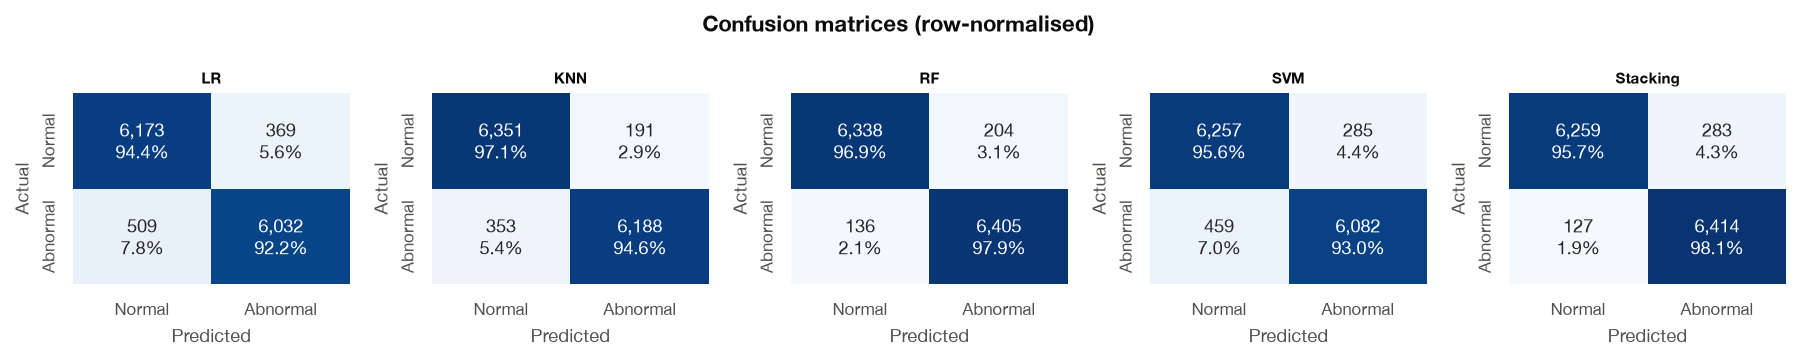

> **Figure 12 — Confusion matrices on the held-out test set**  
> *What it shows:* 2×2 table per model: rows = truth, columns = prediction. Each row adds up to 100 %.  
> *How to read it:* The diagonal holds the hits. The bottom-left cell is the sick cases the model missed: the most dangerous error.

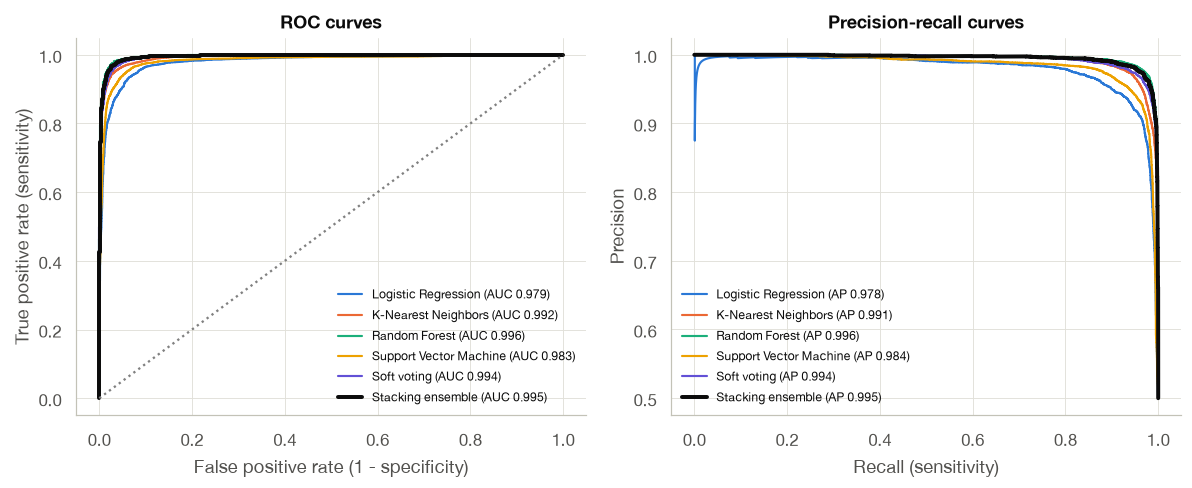

> **Figure 13 — ROC and precision-recall curves**  
> *What it shows:* How hits and false alarms change as the decision threshold moves. The area under the curve (AUC) sums it up.  
> *How to read it:* A curve hugging the top-left (ROC) or top-right (PR) corner is better. The dotted diagonal is chance (AUC 0.5).

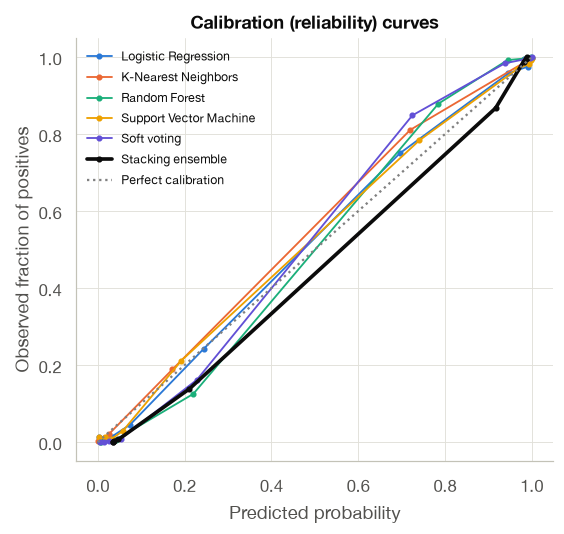

> **Figure 14 — Reliability of the predicted probabilities**  
> *What it shows:* Cases are grouped by predicted probability and compared with the real share of positives.  
> *How to read it:* On the diagonal, '70 %' really means 7 out of 10 such cases are positive. Below it, the model over-estimates.

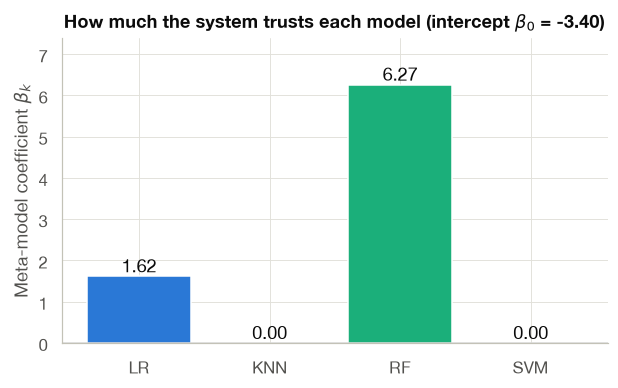

> **Figure 15 — Coefficients learned by the meta-model for each base model**  
> *What it shows:* Weights β learned by the meta-model: P = σ(β₀ + Σ βₖ·pₖ). They are ≥ 0 by design.  
> *How to read it:* Taller bar = the final answer listens more to that model. A weight of 0 means the others already carry its information.

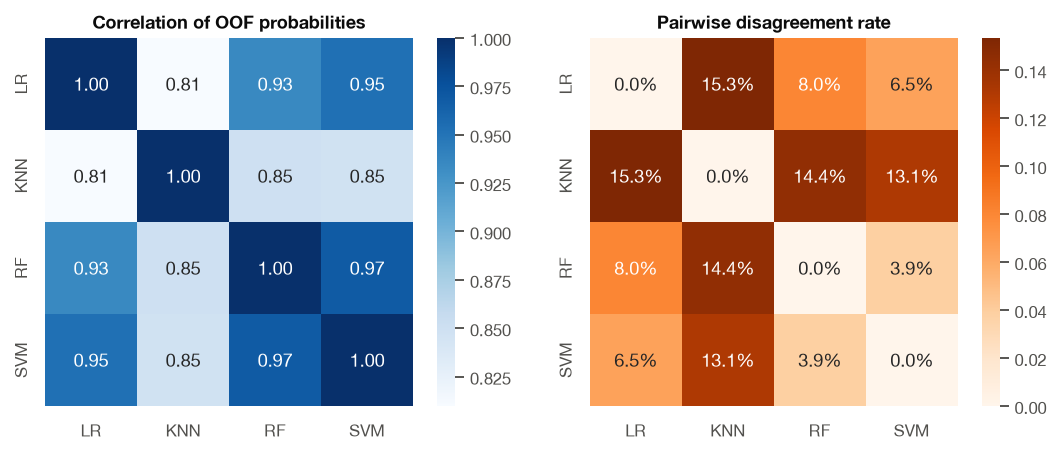

> **Figure 16 — Diversity between base models (OOF correlation and disagreement)**  
> *What it shows:* Left: correlation between the probabilities of each pair of models. Right: % of cases where they disagree.  
> *How to read it:* Combining models only helps if they sometimes disagree: correlations below 1 and non-zero disagreement mean complementary models.

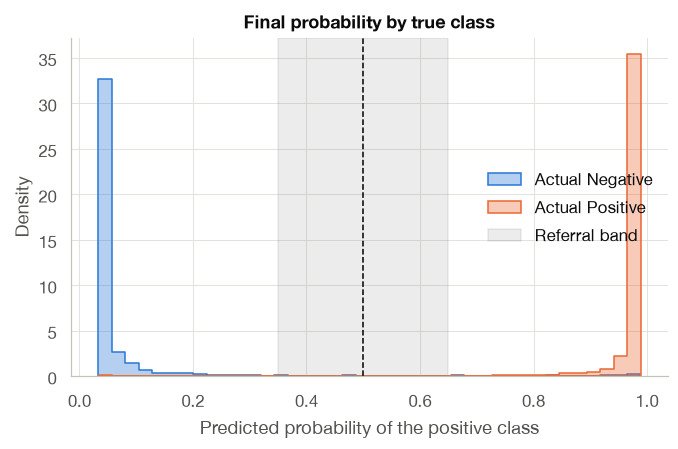

> **Figure 17 — Distribution of the final probability per true class and referral band**  
> *What it shows:* Histogram of the system's probability, one colour per true class. The grey band is the doubt zone.  
> *How to read it:* Ideal: one colour near 0 and the other near 1. Errors live where colours overlap; cases in the grey band go to a clinician.

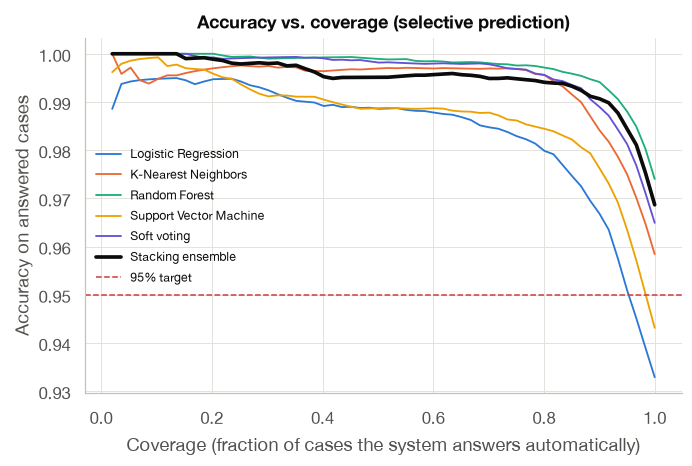

> **Figure 18 — Accuracy when the system answers only its most confident cases**  
> *What it shows:* Cases are sorted from most to least confident; for each share answered (coverage) the accuracy is computed.  
> *How to read it:* Towards the left the system answers fewer cases and gets more right. Where the curve crosses the 95 % line tells which share of cases it can solve on its own at that accuracy.

,accuracy,precision,recall_sensitivity,specificity,f1,roc_auc,mcc
Logistic Regression,0.9329,0.9424,0.9222,0.9436,0.9322,0.9789,0.8660
K-Nearest Neighbors,0.9584,0.9701,0.9460,0.9708,0.9579,0.9917,0.9171
Random Forest,0.9740,0.9691,0.9792,0.9688,0.9741,0.9959,0.9481
Support Vector Machine,0.9431,0.9552,0.9298,0.9564,0.9424,0.9832,0.8866
Hard voting,0.9650,0.9664,0.9635,0.9665,0.9649,NaN,0.9300
Soft voting,0.9649,0.9666,0.9632,0.9667,0.9649,0.9938,0.9298
Stacking ensemble,0.9687,0.9577,0.9806,0.9567,0.9690,0.9950,0.9376


In [8]:
wf.evaluate()
wf.results['test_metrics'][['accuracy', 'precision', 'recall_sensitivity', 'specificity', 'f1', 'roc_auc', 'mcc']].round(4)

## 8. Explainability
Permutation importance of the rhythm features and of three waveform regions (P wave, QRS complex, ST-T).

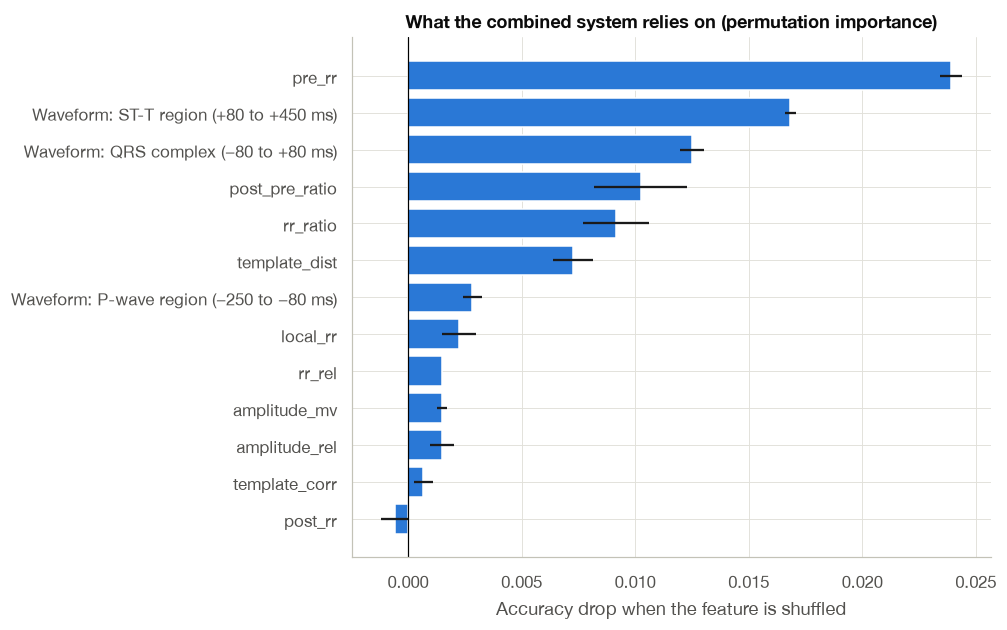

> **Figure 19 — Permutation importance of each feature group for the ensemble**  
> *What it shows:* Permutation importance: how much accuracy drops when one input is randomly shuffled.  
> *How to read it:* Longer bar = the system depends more on that input. Bars near 0 = it could be removed without losing accuracy.

,feature_group,n_columns,importance,std
0,pre_rr,1,0.023917,0.000471
12,Waveform: ST-T region (+80 to +450 ms),47,0.016833,0.000236
11,Waveform: QRS complex (−80 to +80 ms),21,0.012500,0.000540
4,post_pre_ratio,1,0.010250,0.002041
3,rr_ratio,1,0.009167,0.001448
7,template_dist,1,0.007250,0.000890
10,Waveform: P-wave region (−250 to −80 ms),22,0.002833,0.000425
2,local_rr,1,0.002250,0.000736
9,rr_rel,1,0.001500,0.000000
5,amplitude_mv,1,0.001500,0.000204


In [9]:
wf.explain()
wf.results['importance']

## 9. Results simulation, additional validation (leakage audit, new patients) and monitoring session

1. **Simulation:** twelve held-out beats of every AAMI class go through the 4 models and the meta-model (full trace in
   `tables/simulation_test_beats_trace.json`).
2. **Leakage audit:** share of test beats whose patient is also in training, and share whose most similar training
   beat belongs to the same patient. If both are high, the test of section 7 shares patients with training, as in the standard protocol.
3. **Patient-wise 5-fold cross-validation (additional, strict *inter-patient* analysis):** patients are split into 5 groups; each time the
   system is retrained on 4 groups and tested on the patients of the 5th, never seen before. Reported as mean ± SD,
   per fold and per beat type.
4. **Deployment check:** on the new patients of fold 1, beats are located by the automatic detector (XQRS) and
   classified exactly as the web app does.
5. **Monitoring session:** a simulated remote-monitoring strip of a new patient, beat by beat.

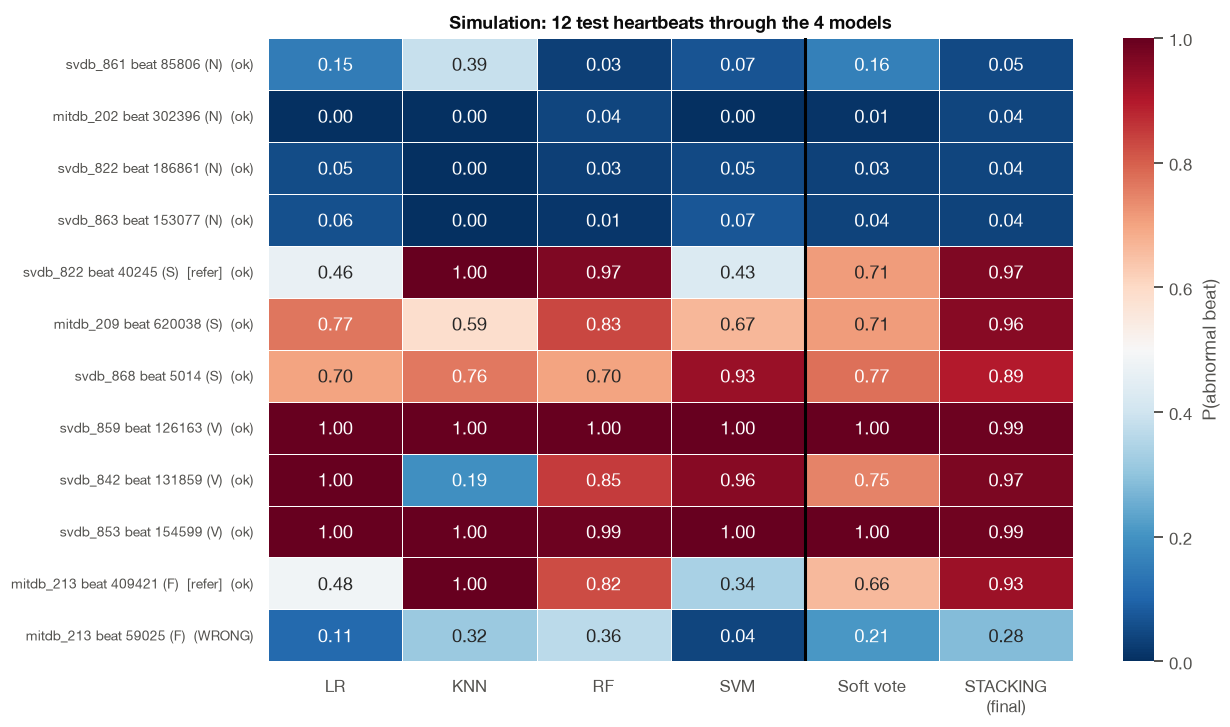

> **Figure 20 — Per-model and final probability for 12 held-out beats of every AAMI class**  
> *What it shows:* Beats of each type (N, S, V, F) not used for training (split by beat), with each model's probability and the final answer.  
> *How to read it:* Blue = normal, red = abnormal. '(WRONG)' marks the errors; S beats are the hardest.

[ecg] NOTE: Leakage audit: 100% of the beat-level test beats come from patients also seen in training, and for 94% of them the nearest training beat is from the same patient. The beat-level accuracy therefore measures performance on KNOWN patients; patient_cv() measures it on NEW patients.
{
  "test_beats_from_training_patients": 1.0,
  "nearest_training_beat_same_patient": 0.944,
  "patients_in_train": 121,
  "patients_in_test": 121
}
Patient-wise CV fold 1/5: 98 training patients, 23 new test patients ...


  Logistic Regression: OOF + final fit done in 2.3s


  K-Nearest Neighbors: OOF + final fit done in 1.6s


  Random Forest: OOF + final fit done in 51.2s


...

  Logistic Regression: OOF + final fit done in 1.3s


  K-Nearest Neighbors: OOF + final fit done in 2.4s


  Random Forest: OOF + final fit done in 42.4s


  Support Vector Machine: OOF + final fit done in 48.5s


Patient-wise CV stacking accuracy: 90.46% ± 4.42%


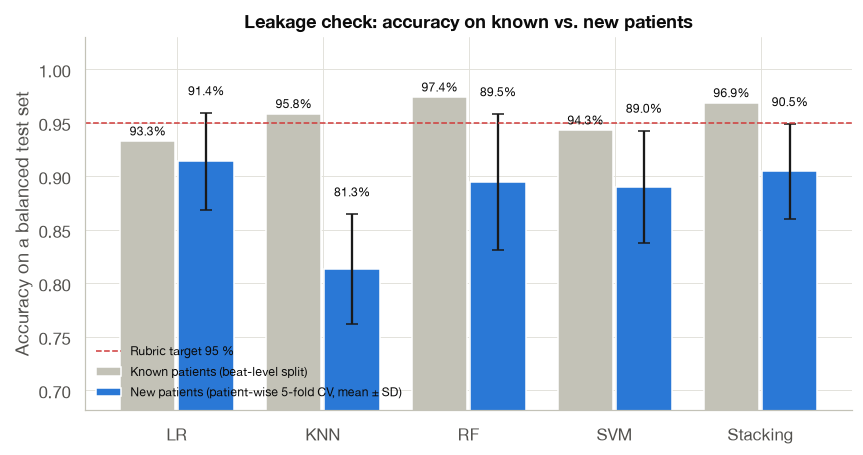

> **Figure 21 — Accuracy with a beat-level split (known patients) vs. patient-wise CV (new patients)**  
> *What it shows:* Accuracy of each model with two ways of splitting the data: at random by beat (the same patient can be in training and test) and by patient (test patients were never seen).  
> *How to read it:* The official figure is the grey bar (split by beat, the standard MIT-BIH protocol). The coloured bar is an additional analysis: it shows how much accuracy drops when the patient is completely new.

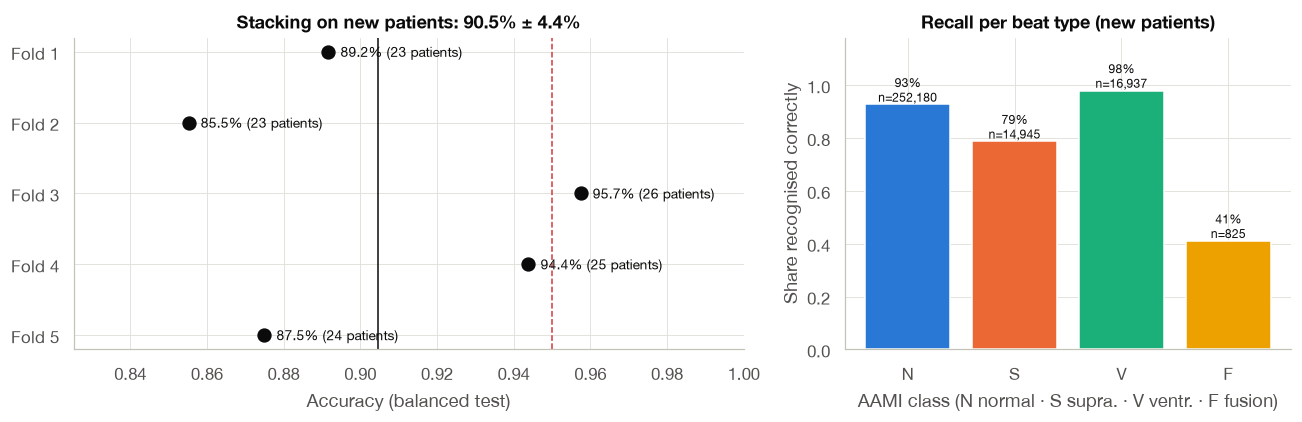

> **Figure 22 — Patient-wise 5-fold CV: accuracy per fold and recall per AAMI class**  
> *What it shows:* Patients are split into 5 groups; each time the system trains on 4 and is tested on the remaining one, never sharing patients.  
> *How to read it:* Each dot is one fold. If they all sit close together, the result does not depend on which patients ended up in the test.

Automatic beat detection on 24 unseen records ...


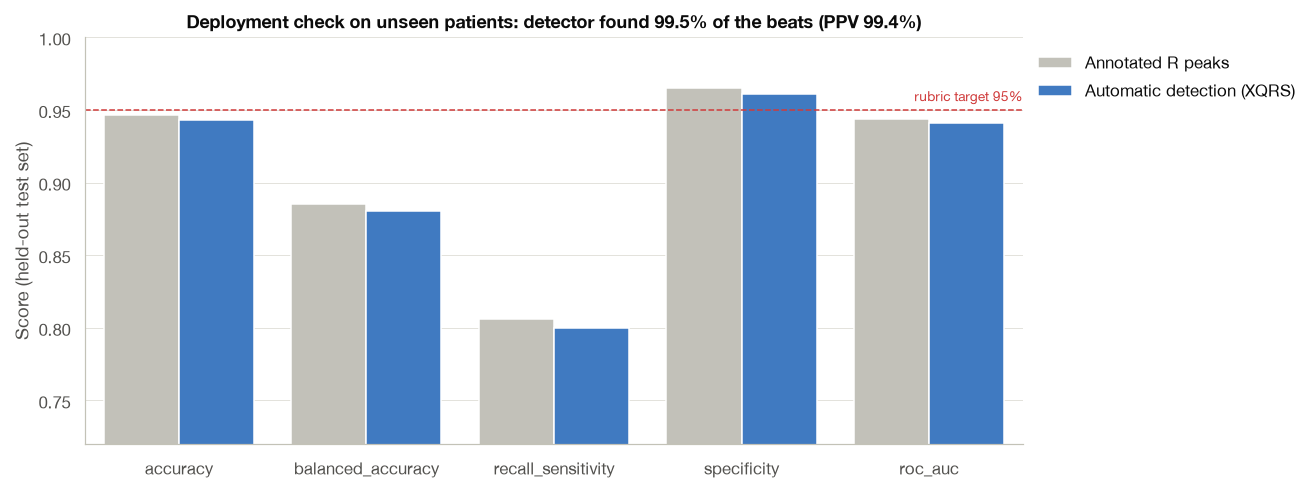

> **Figure 23 — Annotated vs. automatically detected beats on unseen patients**  
> *What it shows:* Compares classifying the beats marked by the cardiologist with the ones the automatic detector (XQRS) finds, as the app does.  
> *How to read it:* If both bars are almost equal, the app works on unannotated ECGs without losing accuracy.

{
  "detection_sensitivity": 0.9953491687307329,
  "detection_ppv": 0.9936140313428322,
  "classified_beats": 55741,
  "accuracy": 0.943040132039253,
  "balanced_accuracy": 0.880535135841437,
  "recall_sensitivity": 0.800032097576633,
  "specificity": 0.9610381741062411,
  "roc_auc": 0.9407648267092291
}


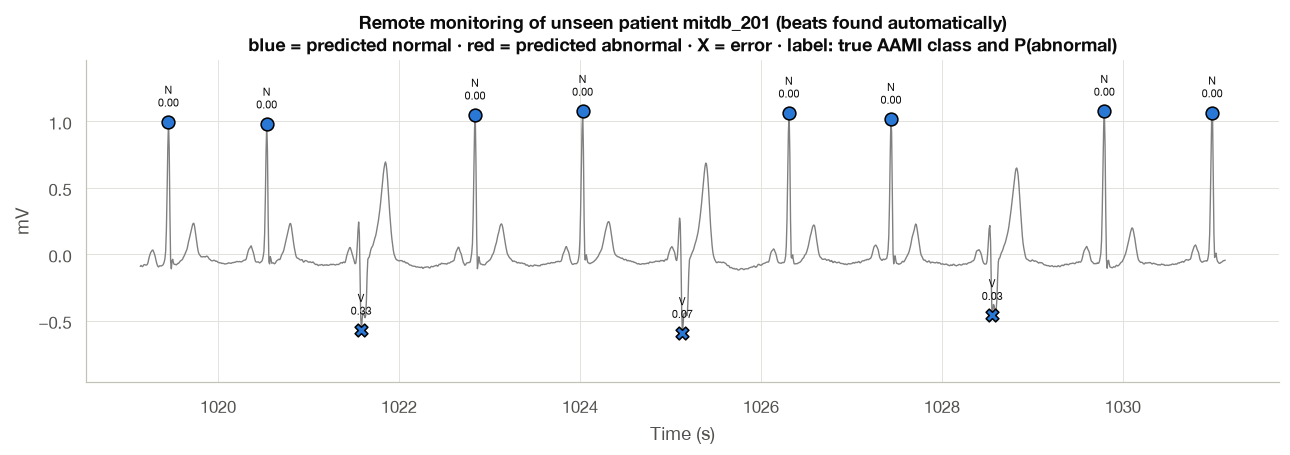

> **Figure 24 — Simulated monitoring session on unseen record mitdb_201**  
> *What it shows:* A stretch of an unseen patient's ECG with the system's prediction for every beat.  
> *How to read it:* Blue = predicted normal, red = predicted abnormal, X = error. Under each beat: its true class and the probability.

{
  "test_beats_from_training_patients": 1.0,
  "nearest_training_beat_same_patient": 0.944,
  "patients_in_train": 121,
  "patients_in_test": 121
}


accuracy         recall_sensitivity         specificity         roc_auc         natural_accuracy         natural_balanced_accuracy  \
                           mean     std               mean     std        mean     std    mean     std             mean     std                      mean   
model                                                                                                                                                       
K-Nearest Neighbors      0.8131  0.0515             0.7381  0.1031      0.8880  0.0686  0.8878  0.0419           0.9230  0.0360                    0.7702   
Logistic Regression      0.9140  0.0451             0.8889  0.0951      0.9390  0.0112  0.9609  0.0278           0.9452  0.0191                    0.8421   
Random Forest            0.8945  0.0636             0.8413  0.1196      0.9478  0.0099  0.9688  0.0204           0.9458  0.0240                    0.7914   
Stacking ensemble        0.9046  0.0442             0.8789  0.0854      0.9303  0.0167  0.9695  0.0202           0.9525  0.0203                    0.8794   
Support Vector Machine   0.8903  0.0524             0.8368  0.1017      0.9437  0.0114  0.9598  0.0236           0.9497  0.0232                    0.8454   

                                
                           std  
model                           
K-Nearest Neighbors     0.0656  
Logistic Regression     0.0694  
Random Forest           0.0773  
Stacking ensemble       0.0672  
Support Vector Machine  0.0718

In [10]:
wf.simulate()
print(json.dumps(wf.results['leakage'], indent=2))
wf.results['patient_cv_summary'].round(4)

## 10. Export and traceability report

In [11]:
wf.export()
path = wf.tracker.finalize()
print(open(wf.tracker.root / 'TRACEABILITY.md').read()[:3000])

# Traceability report — ecg tier

Run: 2026-10-27T09:34:38 → 2026-10-27T09:51:16 · seed 42 · Python 3.14.7 · scikit-learn 1.9.1

## Inputs

| File | Description | SHA-256 |
|---|---|---|
| `data/raw/ecg/mitdb.zip` | PhysioNet mitdb v1.0.0 (ODC-By 1.0) | `47b26926927c11bd…` |
| `data/raw/ecg/svdb.zip` | PhysioNet svdb v1.0.0 (ODC-By 1.0) | `ef0cf2aae4523410…` |

## Data lineage

| # | Step | Rows before | Rows after | Removed | Detail |
|---|---|---|---|---|---|
| 1 | Segment beats (mitdb) | 0 | 100,630 | -100,630 | 44 records read, 4 paced records excluded (102, 104, 107, 217) |
| 2 | Segment beats (svdb) | 0 | 184,347 | -184,347 | 78 records read, 0 paced records excluded (none) |
| 3 | Remove non-finite values | 284,977 | 284,977 | 0 | NaN or infinite values in any numeric column |
| 4 | Filter implausible RR intervals (20-300 bpm) | 284,977 | 284,887 | 90 | pre_rr outside [0.2, 3.0]: 44; post_rr outside [0.2, 3.0]: 46 |
| 5 | Balance classes (random undersampling) | 284,887 | 65,414